In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

# setting pandas display options
pd.set_option("display.float_format", lambda x: f"{x:.5g}")
pd.set_option("display.max_columns", None)


# versions
print(sys.executable)
print('pandas', pd.__version__)

/Users/qusaislaptop/miniconda3/envs/fnol_env/bin/python
pandas 3.1.0


In [3]:
from pathlib import Path
import sys

# Locate the project root and ensure the src directory is in the sys.path
project_root = Path.cwd()
while project_root != project_root.parent and not (project_root / "src").is_dir():
    project_root = project_root.parent

src_dir = project_root / "src"
if not src_dir.is_dir():
    raise FileNotFoundError("Could not locate the src directory from the notebook's working directory.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for path in sorted(src_dir.rglob("*")):
    kind = "DIR " if path.is_dir() else "FILE"
    # print(f"{kind} {path.relative_to(project_root)}")

# import helper functions
from src.data.loaders import load_excel
from src.utils.utils import replace_abnormal_entries

# Reading The Data 

In [4]:
df = load_excel("/Users/qusaislaptop/Projects/data_science/hastings_case_study/data/raw/Data_Scientist_Interview_FNOL_Data.xlsx")
df.head()

,claim number,date_of_loss,notifier,loss_code,loss_description,notification_period,inception_to_loss,location_of_incident,weather_conditions,vehicle_mobile,time_hour,main_driver,ph_considered_tp_at_fault,vechile_registration_present,incident_details_present,injury_details_present,tp_type_insd_pass_back,tp_type_insd_pass_front,tp_type_driver,tp_type_pass_back,tp_type_pass_front,tp_type_bike,tp_type_cyclist,tp_type_pass_multi,tp_type_pedestrian,tp_type_other,tp_type_nk,tp_injury_whiplash,tp_injury_traumatic,tp_injury_fatality,tp_injury_unclear,tp_injury_nk,tp_region_eastang,tp_region_eastmid,tp_region_london,tp_region_north,tp_region_northw,tp_region_outerldn,tp_region_scotland,tp_region_southe,tp_region_southw,tp_region_wales,tp_region_westmid,tp_region_yorkshire,incurred,capped incurred
0,1,2003-04-15,PH,LD003,Head on collision,22,13,Main Road,NORMAL,Y,10,Other,n/k,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,2,2003-04-20,CNF,LD003,Head on collision,1,9,Main Road,WET,Y,18,Other,n/k,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,2801.3,2801.3
2,3,2003-04-24,CNF,LD003,Head on collision,5,17,Main Road,WET,Y,16,Y,n/k,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1220.9,1220.9
3,4,2003-05-13,CNF,LD003,Head on collision,1,23,Main Road,N/K,Y,14,Other,n/k,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,3529.9,3529.9
4,5,2003-06-11,CNF,LD003,Head on collision,1,48,Other,N/K,N,9,Other,n/k,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,3156,3156


# EDA

In [5]:
###### Features categories

#### Claim related features
# claim number 
# loss descritpion
# notifier
# loss code 
# injury details present 
# incident details present 

### date features 
# date of loss
# inception to loss 
# notification period 
# time hour 

### location data 
# location of incident 

### driver data 
# main driver 

### vehicle data 
# vehicle regestiration present 
# vehicle mobile 

### weather data 
# weather conditions 

### TP data 
# rest of features  

In [6]:
print(df.shape)

(7691, 46)


In [7]:
# noticed some abnormal entries in the data like N/k, n/k, #
# will replace them with np.nan
print(df['ph_considered_tp_at_fault'].value_counts(), '\n')
print(df['location_of_incident'].value_counts())

# apply the function to replace abnormal entries
df = replace_abnormal_entries(df)


ph_considered_tp_at_fault
N      4855
n/k    2654
Y       181
#         1
Name: count, dtype: int64 

location_of_incident
Minor Road        4249
Main Road         2702
Car Park           225
n/k                213
Other              117
Home Address       104
Not Applicable      56
Motorway            25
Name: count, dtype: int64


In [8]:
# checking null counts in each column after replacing abnormal entries
print(df.isnull().sum().sort_values(ascending=False)/df.shape[0] * 100)

ph_considered_tp_at_fault      34.521
weather_conditions             10.337
vehicle_mobile                  5.747
location_of_incident           2.7695
tp_region_northw                    0
tp_injury_whiplash                  0
tp_injury_traumatic                 0
tp_injury_fatality                  0
tp_injury_unclear                   0
tp_injury_nk                        0
tp_region_eastang                   0
tp_region_eastmid                   0
tp_region_london                    0
tp_region_north                     0
claim number                        0
tp_region_outerldn                  0
tp_type_other                       0
tp_region_scotland                  0
tp_region_southe                    0
tp_region_southw                    0
tp_region_wales                     0
tp_region_westmid                   0
tp_region_yorkshire                 0
incurred                            0
tp_type_nk                          0
tp_type_pass_multi                  0
tp_type_pede

In [9]:
df.describe(include='all').transpose()

#### notes 
# notfication period has negative values 
# tp_type_insd_pass_front is all zeros 
# tp_type_pass_multi is all zeros
# loss code and loss description have only one value
# try creating cyclical/new time based features from existing time based features 

### columns not sure what they mean 
# tp_type_insd_pass_back
# tp_type_insd_pass_back
# tp_type_driver
# tp_type_pass_back
# tp_type_pass_front


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
claim number,7691,NaN,NaN,NaN,3846,2220.3,1,1923.5,3846,5768.5,7691
date_of_loss,7691,3175,2014-05-08,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
notifier,7691,5,PH,3807,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loss_code,7691,1,LD003,7691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loss_description,7691,1,Head on collision,7691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
notification_period,7691,NaN,NaN,NaN,7.1634,39.138,-18,0,1,2,1042
inception_to_loss,7691,NaN,NaN,NaN,166.85,104.45,0,75,161,253,365
location_of_incident,7478,7,Minor Road,4249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_conditions,6896,3,NORMAL,4564,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_mobile,7249,2,Y,4046,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# dropping the following columns as they have only one value
df.drop(columns=['loss_code', 'loss_description', 'tp_type_insd_pass_front', 'tp_type_pass_multi'], inplace=True)
print("shape of df after dropping columns:", df.shape)

shape of df after dropping columns: (7691, 42)


In [11]:
# checking notification period column 
# 3 rows where the notification period is negative
print((df['notification_period'] < 0).sum(), '\n')

 # notificaiton period description > 0 
print(df[df['notification_period'] >= 0]['notification_period'].describe(), '\n')

# will impute the negative notification values with the median of the positive notification periods (median = 1)
median_notification_period = df[df['notification_period'] >= 0]['notification_period'].median()
print(f"Median notification period: {median_notification_period}", '\n')
df.loc[df['notification_period'] < 0, 'notification_period'] = median_notification_period

# checking if there are any negative notification periods left
print((df['notification_period'] < 0).sum(), '\n')

print(df['notification_period'].describe(), '\n')



3 

count     7688
mean     7.169
std     39.145
min          0
25%          0
50%          1
75%          2
max       1042
Name: notification_period, dtype: float64 

Median notification period: 1.0 

0 

count     7691
mean    7.1666
std     39.137
min          0
25%          0
50%          1
75%          2
max       1042
Name: notification_period, dtype: float64 



In [12]:
# changing dtype to datetime 
df['date_of_loss'] = pd.to_datetime(df['date_of_loss'])
# checking dtypes 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7691 entries, 0 to 7690
Data columns (total 42 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   claim number                  7691 non-null   int64         
 1   date_of_loss                  7691 non-null   datetime64[us]
 2   notifier                      7691 non-null   str           
 3   notification_period           7691 non-null   int64         
 4   inception_to_loss             7691 non-null   int64         
 5   location_of_incident          7478 non-null   str           
 6   weather_conditions            6896 non-null   str           
 7   vehicle_mobile                7249 non-null   str           
 8   time_hour                     7691 non-null   int64         
 9   main_driver                   7691 non-null   str           
 10  ph_considered_tp_at_fault     5036 non-null   str           
 11  vechile_registration_present  7691 non-nu

## The Target 

In [13]:
# 198 large loss claims above 50k 
# 1754 claims with zero incurred, claims that haven't been paid off yet 
# 48 claims with negative incurred
print(df['capped incurred'].describe(), "\n")
print(df['incurred'].describe(), "\n")

print(f"number of negative capped incurred: {(df['capped incurred'] < 0).sum()}")
print(f"number of negative incurred: {(df['incurred'] < 0).sum()}")

print(f"number of zero capped incurred: {(df['capped incurred'] == 0).sum()}")
print(f"number of zero incurred: {(df['incurred'] == 0).sum()}")

print(f"number of incurred greater than 50k: {(df['incurred'] > 50000).sum()}")

count     7691
mean    6106.9
std      11057
min     -10539
25%     24.909
50%     1237.7
75%     6258.4
max      50000
Name: capped incurred, dtype: float64 

count         7691
mean        9423.3
std          49852
min         -10539
25%         24.909
50%         1237.7
75%         6258.4
max     1.9519e+06
Name: incurred, dtype: float64 

number of negative capped incurred: 48
number of negative incurred: 48
number of zero capped incurred: 1754
number of zero incurred: 1754
number of incurred greater than 50k: 198


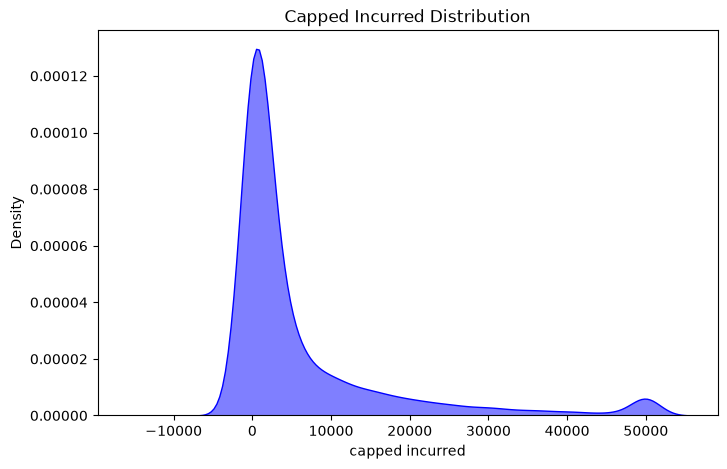

In [14]:
# plotting capped incurred distribution
plt.figure(figsize=(8,5))
sns.kdeplot(df['capped incurred'], label='Capped Incurred', shade=True, alpha=0.5,color='blue')
plt.title('Capped Incurred Distribution')
plt.show()

# Features/Target Engineering 

In [32]:
# import helper functions for feature engineering
from src.features.build_features import (build_aggregate_features, build_time_features, 
                                         add_targets, print_target_summary, 
                                         select_final_columns, set_categorical_dtypes, 
                                         check_feature_dtypes)
from src.utils.utils import save_preprocessed_data

In [16]:
# build time based/cyclical features
df = build_time_features(df)

# build third party and region aggregate features 
df = build_aggregate_features(df)

In [17]:
df.shape

(7691, 67)

In [18]:
# adding engineered targets to the df 
# y_capped, y_large, and y_incurred
df = add_targets(df)

In [19]:
# Print summary of target columns (y_capped, y_large, y_incurred)
print_target_summary(df)

Negative incurred floored to 0: 48
Share of claims with zero cost: 23.4%
Large claims (> 50,000): 198 (2.6%)
Large claims' share of total cost: 48.8%


In [20]:
# Compute Spearman correlations of numeric features with severity target y_capped
spearman_correlations = (
    df.select_dtypes(include="number")
    .drop(columns=["y_capped", "y_incurred", "incurred", "capped incurred", 'y_large'])
    .corrwith(df["y_capped"], method="spearman")
    .sort_values(ascending=False)
    .rename("spearman_correlation")
    .to_frame()
)

display(spearman_correlations.head(10))

,spearman_correlation
inj_known_share,0.52123
inj_flagged_n,0.51924
inj_severity_ord,0.50961
inj_per_tp,0.50651
tp_injury_whiplash,0.47254
tp_n_total,0.36217
tp_type_pass_front,0.2852
tp_injury_traumatic,0.23521
tp_type_pass_back,0.21648
tp_type_other,0.2073


In [21]:
# final cleaned df 
df = select_final_columns(df)
print(df.shape)
# Save the final preprocessed dataframe
save_preprocessed_data(df)

(7691, 55)


PosixPath('/Users/qusaislaptop/Projects/data_science/hastings_case_study/data/preporcessed/preprocessed.csv')

# Model Tuning/Training

In [48]:
# import helper functions and config variables
from src.models.train_test_split import check_model_table, add_split_column, print_split_summary, get_baseline_deviance
from src.config import FEATURE_COLS, CATEGORICAL_COLS, N_TRIALS

from src.models.tuning import * 
from src.models.train import * 

In [33]:
# loading the preprocessed data 
df= pd.read_csv("/Users/qusaislaptop/Projects/data_science/hastings_case_study/data/preporcessed/preprocessed.csv")

# convert categorical columns to category dtype for XGBoost
df = set_categorical_dtypes(df, CATEGORICAL_COLS)

#check dtypes in df 
check_feature_dtypes(df, FEATURE_COLS)

df['date_of_loss'] = pd.to_datetime(df['date_of_loss'])
df = df.reset_index(drop=True)

print(df.shape)
df.head()

Columns with unsupported dtypes: []
(7691, 55)


,claim_number,date_of_loss,notifier,location_of_incident,weather_conditions,vehicle_mobile,main_driver,ph_considered_tp_at_fault,loss_season,loss_month,loss_day_of_week,time_hour,notification_period,inception_to_loss,loss_is_weekend,loss_hour_sin,loss_hour_cos,loss_month_sin,loss_month_cos,loss_day_of_week_sin,loss_day_of_week_cos,loss_day_of_year_sin,loss_day_of_year_cos,vehicle_registration_present,incident_details_present,injury_details_present,tp_type_insd_pass_back,tp_type_driver,tp_type_pass_back,tp_type_pass_front,tp_type_bike,tp_type_cyclist,tp_type_pedestrian,tp_type_other,tp_type_nk,tp_injury_whiplash,tp_injury_traumatic,tp_injury_fatality,tp_injury_unclear,tp_injury_nk,tp_n_total,inj_flagged_n,inj_severity_ord,inj_per_tp,inj_known_share,tp_reg_east,tp_reg_london,tp_reg_midlands,tp_reg_north,tp_reg_scotland,tp_reg_south,tp_reg_wales,y_incurred,y_capped,y_large
0,1,2003-04-15,PH,Main Road,NORMAL,Y,Other,NaN,Spring,4,1,10,22,13,0,0.5,-0.86603,0.86603,-0.5,0.78183,0.62349,0.97212,-0.23449,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0
1,2,2003-04-20,CNF,Main Road,WET,Y,Other,NaN,Spring,4,6,18,1,9,1,-1,-1.837e-16,0.86603,-0.5,-0.78183,0.62349,0.94836,-0.31719,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,2801.3,2801.3,0
2,3,2003-04-24,CNF,Main Road,WET,Y,Y,NaN,Spring,4,3,16,5,17,0,-0.86603,-0.5,0.86603,-0.5,0.43388,-0.90097,0.92429,-0.38169,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1220.9,1220.9,0
3,4,2003-05-13,CNF,Main Road,NaN,Y,Other,NaN,Spring,5,1,14,1,23,0,-0.5,-0.86603,0.5,-0.86603,0.78183,0.62349,0.75267,-0.6584,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,3529.9,3529.9,0
4,5,2003-06-11,CNF,Other,NaN,N,Other,NaN,Summer,6,2,9,1,48,0,0.70711,-0.70711,1.2246e-16,-1,0.97493,-0.22252,0.34561,-0.93838,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,3156,3156,0


In [34]:
# checks on the df for Nan values, target, features and unique index 
check_model_table(df, FEATURE_COLS, CATEGORICAL_COLS)

NaNs in numeric features: 0
Ids/targets/split inside the feature list: []
Index unique: True


In [35]:
# split the data into train, validation folds, and oos sets
df = add_split_column(df)
print_split_summary(df)

             rows      first       last
split                                  
oos          2399 2014-01-01 2015-06-30
train_valid  5292 2003-04-15 2013-12-31
fold 1: train 2,875 rows, valid 576 rows
fold 2: train 3,451 rows, valid 829 rows
fold 3: train 4,280 rows, valid 1,012 rows


In [36]:
baseline_dev = get_baseline_deviance(df)
print(f"Baseline Tweedie deviance (CV): {baseline_dev:.1f}")

Baseline Tweedie deviance (CV): 218.7


## Tuning the Models 

In [38]:
help(tune_severity)

Help on function tune_severity in module src.models.tuning:

tune_severity(df: pandas.DataFrame, feature_cols: list, n_trials: int = 60) -> dict



In [40]:
# capped severity model for 100 trials 
best_severity = tune_severity(df, FEATURE_COLS, n_trials=N_TRIALS)

[I 2026-10-30 20:49:00,303] A new study created in memory with name: no-name-21111cfe-0bc8-4751-9c71-8115ab7c3242


[I 2026-10-30 20:49:03,013] Trial 0 finished with value: 138.2862793966602 and parameters: {'tweedie_variance_power': 1.449816047538945, 'monotone': True, 'max_depth': 4, 'learning_rate': 0.014322493718230255, 'min_child_weight': 143.57772931903781, 'subsample': 0.6232334448672797, 'colsample_bytree': 0.9330880728874675, 'reg_lambda': 15.930522616241015, 'reg_alpha': 0.6796578090758157, 'gamma': 0.10292247147901223}. Best is trial 0 with value: 138.2862793966602.
[I 2026-10-30 20:49:05,828] Trial 1 finished with value: 140.7084558613335 and parameters: {'tweedie_variance_power': 1.6879639408647977, 'monotone': True, 'max_depth': 2, 'learning_rate': 0.015254729458052608, 'min_child_weight': 284.1728127339013, 'subsample': 0.8099025726528951, 'colsample_bytree': 0.7159725093210578, 'reg_lambda': 3.8234752246751853, 'reg_alpha': 0.280163515871626, 'gamma': 0.6974693032602092}. Best is trial 0 with value: 138.2862793966602.
[I 2026-10-30 20:49:08,594] Trial 2 finished with value: 136.20060

tweedie_deviance_p1.5: baseline 218.7406 -> best 135.0212 (n_estimators = 332, fold iterations = [471, 315, 119])


In [41]:
# large loss model for 100 trials 
best_large_loss = tune_large(df, FEATURE_COLS, n_trials=N_TRIALS)

[I 2026-10-30 20:55:27,369] A new study created in memory with name: no-name-a5108ae6-b37c-477c-9f93-a00498b694a8
[I 2026-10-30 20:55:29,322] Trial 0 finished with value: 0.09895445186115451 and parameters: {'monotone': False, 'max_depth': 3, 'learning_rate': 0.03968793330444373, 'min_child_weight': 0.18410729205738682, 'subsample': 0.662397808134481, 'colsample_bytree': 0.5290418060840998, 'reg_lambda': 53.99484409787433, 'reg_alpha': 0.25378155082656645, 'gamma': 3.540362888980227}. Best is trial 0 with value: 0.09895445186115451.
[I 2026-10-30 20:55:30,763] Trial 1 finished with value: 0.09737151928434389 and parameters: {'monotone': False, 'max_depth': 3, 'learning_rate': 0.016305687346221478, 'min_child_weight': 0.20366442026830908, 'subsample': 0.6733618039413735, 'colsample_bytree': 0.6521211214797689, 'reg_lambda': 11.207606211860567, 'reg_alpha': 0.05342937261279776, 'gamma': 1.4561457009902097}. Best is trial 1 with value: 0.09737151928434389.
[I 2026-10-30 20:55:31,855] Tria

logloss: baseline 0.1432 -> best 0.0963 (n_estimators = 848, fold iterations = [1349, 652, 311])


In [42]:
# saving hyperparms 
save_best_params(best_severity,"/Users/qusaislaptop/Projects/data_science/hastings_case_study/reports/tuning_params/best_severity_params.json")
save_best_params(best_large_loss,"/Users/qusaislaptop/Projects/data_science/hastings_case_study/reports/tuning_params/best_large_loss_params.json")

## Training the models 

In [49]:
severity_models, large_models, mean_excess, oos_preds = train_and_score_oos(
    df, FEATURE_COLS, best_severity, best_large_loss
)

print(f"Mean excess over cap: £{mean_excess:,.0f}")


Mean excess over cap: £131,270


In [50]:
oos = df[df[config.SPLIT_COL] == config.SPLIT_OOS].join(oos_preds)
get_feature_importance(severity_models).head(15)


inj_known_share               0.2969
inj_per_tp                    0.1004
inj_flagged_n               0.073329
tp_n_total                  0.062285
vehicle_mobile               0.04121
tp_injury_unclear           0.041179
inj_severity_ord            0.040822
inception_to_loss           0.031374
tp_type_other               0.025813
loss_day_of_year_cos         0.02181
loss_day_of_year_sin          0.0194
notification_period         0.018843
tp_type_nk                  0.018053
time_hour                   0.014349
ph_considered_tp_at_fault   0.014095
Name: gain_share, dtype: float64

In [51]:
severity_models_full, large_models_full = fit_bagged_models(df, FEATURE_COLS, best_severity, best_large_loss)
mean_excess_full = get_mean_excess_over_cap(df)
# save_models(severity_models_full, large_models_full, "models_full")

In [52]:
severity_models_full

[XGBRegressor(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.511679134511437, device=None,
              early_stopping_rounds=None, enable_categorical=True,
              eval_metric=None, feature_types=None, feature_weights=None,
              gamma=0.5743842888461244, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.026485393861081313,
              max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=691.7925218013585, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=332,
              n_jobs=None, num_parallel_tree=None, ...),
 XGBRegressor(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.511679134511437, d

In [54]:
print(get_feature_importance(severity_models_full).head(15), "\n")
print(get_feature_importance(large_models_full).head(15), "\n")

inj_known_share              0.31692
inj_per_tp                  0.098028
inj_flagged_n               0.083007
tp_n_total                  0.056316
inj_severity_ord            0.055529
vehicle_mobile              0.051604
tp_injury_unclear           0.031642
inception_to_loss           0.026342
tp_type_other               0.020252
notification_period         0.019005
loss_day_of_year_sin        0.018554
loss_day_of_year_cos        0.017595
tp_injury_nk                0.015993
ph_considered_tp_at_fault   0.013783
tp_injury_whiplash          0.012928
Name: gain_share, dtype: float64 

tp_n_total                 0.37652
inj_severity_ord           0.12595
inj_per_tp                0.097222
inj_known_share           0.081194
tp_type_other              0.03935
vehicle_mobile            0.032306
notification_period       0.026551
injury_details_present    0.026525
inj_flagged_n             0.016248
location_of_incident      0.015503
tp_injury_traumatic       0.015256
time_hour                